# Etapa 4: Classificação Supervisionada com Mascaramento Léxico e Explicabilidade

Neste notebook final, avaliamos se as teses e dissertações em Inteligência Artificial possuem uma **assinatura vocabular de contexto própria** (tarefas, bases de dados, métricas de validação), indo além dos termos explícitos que definem a área:
1. **Prevenção de Vazamento de Dados (*Lexical Masking*):** Como o rótulo binário `IA` foi construído a partir do dicionário `lexico_ia.py`, removemos do texto de entrada todas as 68 expressões do dicionário e seus radicais semânticos diretos (`TXT_MASC`).
2. **Benchmark de Três Famílias de Classificadores:** Avaliamos **Random Forest** (*bagging*), **Gradient Boosting - GBM** (*boosting*) e **Linear SVM** (hiperplano de margem máxima calibrado).
3. **Generalização Estratificada vs. Temporal:** Comparamos o desempenho em corte transversal (**80% Treino / 20% Teste Estratificado**) com a capacidade preditiva longitudinal (**Treino 2010–2019 $\rightarrow$ Teste 2020–2024**).
4. **Explicabilidade Curricular e Figura 5 (Padrão SBC):** Extração dos termos de contexto com maior peso positivo e negativo no hiperplano do SVM e geração da Figura 5 em `.pdf` e `.png` (`300 DPI`).

In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

sys.path.insert(0, '../scripts')
import lexico_ia as L

OUT = '../data/resultados'
FIG = '../data/figuras'
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

print("Ambiente de Classificação Supervisionada configurado!")

Ambiente de Classificação Supervisionada configurado!


## 1. Carregamento da Base Processada e Mascaramento dos Termos-Semente
Carregamos o arquivo `base.pkl` gerado na Etapa 3 e aplicamos a remoção rigorosa de todas as ocorrências do `PADRAO_IA` e de fragmentos lexicais derivados (como *convolucional*, *neural*, *aprendizagem*, *fuzzy*, *classificador*).

In [2]:
df = pd.read_pickle(f'{OUT}/base.pkl')

STOP_PT = set("""a ao aos aquela aquelas aquele aqueles aquilo as ate com como da das de dela delas dele deles depois do dos
e ela elas ele eles em entre era essa essas esse esses esta estas este estes eu foi foram ha isso isto ja la lhe mais mas me
mesmo meu minha muito na nas nem no nos nossa nosso num numa o os ou para pela pelas pelo pelos por qual quando que quem se
sem ser seu seus sua suas so tambem te tem ter tu um uma umas uns voce sao esta estao sobre cada assim onde ainda apos bem
pode podem deste desta neste nesta nesse nessa desse dessa todo toda todos todas outro outra outros outras qualquer tal
tese dissertacao trabalho estudo pesquisa objetivo proposta apresenta apresentar propoe propor resultados resultado
abordagem metodo metodos utilizando utilizado utilizada uso partir atraves forma diferentes alem principal sendo""".split())
STOP = list(STOP_PT | set(ENGLISH_STOP_WORDS))

FRAGMENTOS = r'\b\w*(?:neura|deep|profund|convolucion|artificia|classificador|fuzzy|agente|recomend|aleatori|floresta|genetic|evolutiv|enxame|swarm|bayes|perceptron|transformer|minera|mining|learning|vetores de suporte)\w*\b'
df['TXT_MASC'] = df.TXT.str.replace(L.PADRAO_IA, ' ', regex=True).str.replace(FRAGMENTOS, ' ', regex=True)

print(f"Total de documentos carregados: {len(df)} | Proporção de IA: {df['IA'].mean()*100:.2f}%")
df[['AN_BASE', 'GRAU', 'IA', 'TXT_MASC']].head(3)

Total de documentos carregados: 23851 | Proporção de IA: 33.24%


,AN_BASE,GRAU,IA,TXT_MASC
0,2012,Mestrado acadêmico,1,sistema inteligente de baseado no modelo do...
1,2012,Mestrado acadêmico,0,alinhamento espaco-temporal em sistemas multis...
2,2012,Mestrado acadêmico,0,''ubicua: uma tecnica de inspecao de usabilida...


## 2. Treinamento e Avaliação nos Cenários Estratificado (80/20) e Temporal (2010–19 $\rightarrow$ 2020–24)
Ajustamos o vetorizador TF-IDF (`5.000` unigramas/bigramas com `sublinear_tf=True`) estritamente sobre a partição de treino de cada cenário e avaliamos **Random Forest**, **GBM** e **SVM (linear)**.

In [3]:
def criar_vetorizador():
    return TfidfVectorizer(
        ngram_range=(1, 2), min_df=5, max_df=0.5, max_features=5000, 
        sublinear_tf=True, stop_words=STOP, token_pattern=r'(?u)\b[a-z][a-z]{2,}\b'
    )

def instanciar_modelos():
    return {
        'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=42),
        'GBM': GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=42),
        'SVM (linear)': CalibratedClassifierCV(LinearSVC(C=0.5, class_weight='balanced', random_state=42), cv=3),
    }

def avaliar_cenario(Xtr, ytr, Xte, yte, cenario):
    linhas, rocs = [], {}
    for nome, m in instanciar_modelos().items():
        t0 = time.time()
        m.fit(Xtr, ytr)
        prob = m.predict_proba(Xte)[:, 1]
        pred = (prob >= 0.5).astype(int)
        linhas.append({
            'cenario': cenario, 'modelo': nome, 
            'acuracia': accuracy_score(yte, pred),
            'precisao': precision_score(yte, pred), 
            'revocacao': recall_score(yte, pred),
            'f1': f1_score(yte, pred), 
            'auc': roc_auc_score(yte, prob), 
            'tempo_s': time.time() - t0
        })
        fpr, tpr, _ = roc_curve(yte, prob)
        rocs[nome] = (fpr.tolist(), tpr.tolist())
        print(f"[{cenario}] {nome} ({linhas[-1]['tempo_s']:.1f}s) -> F1: {linhas[-1]['f1']:.4f} | ROC-AUC: {linhas[-1]['auc']:.4f}")
    return linhas, rocs

res_clf = []

# Cenário 1: Divisão Estratificada 80/20
tr, te = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df.IA)
v1 = criar_vetorizador()
Xtr1 = v1.fit_transform(df.loc[tr, 'TXT_MASC'])
Xte1 = v1.transform(df.loc[te, 'TXT_MASC'])
l1, roc1 = avaliar_cenario(Xtr1, df.loc[tr, 'IA'], Xte1, df.loc[te, 'IA'], 'Estratificado 80/20')
res_clf += l1

# Cenário 2: Generalização Temporal (Treino 2010-2019 -> Teste 2020-2024)
trt = df.index[df.AN_BASE <= 2019]
tet = df.index[df.AN_BASE >= 2020]
v2 = criar_vetorizador()
Xtr2 = v2.fit_transform(df.loc[trt, 'TXT_MASC'])
Xte2 = v2.transform(df.loc[tet, 'TXT_MASC'])
l2, roc2 = avaliar_cenario(Xtr2, df.loc[trt, 'IA'], Xte2, df.loc[tet, 'IA'], 'Temporal 2010-19 → 2020-24')
res_clf += l2

met = pd.DataFrame(res_clf)
met.to_csv(f'{OUT}/metricas_classificacao.csv', index=False)
met.to_excel(f'{OUT}/metricas_classificacao.xlsx', index=False, sheet_name='Metricas_Supervisionadas')

print("\nTabela Comparativa de Desempenho (Salva em CSV e Excel):")
display(met.round(4))

[Estratificado 80/20] Random Forest (18.1s) -> F1: 0.7375 | ROC-AUC: 0.8880
[Estratificado 80/20] GBM (95.3s) -> F1: 0.7076 | ROC-AUC: 0.8910
[Estratificado 80/20] SVM (linear) (0.9s) -> F1: 0.7210 | ROC-AUC: 0.8876
[Temporal 2010-19 → 2020-24] Random Forest (13.5s) -> F1: 0.7895 | ROC-AUC: 0.8935
[Temporal 2010-19 → 2020-24] GBM (70.8s) -> F1: 0.7050 | ROC-AUC: 0.8887
[Temporal 2010-19 → 2020-24] SVM (linear) (0.6s) -> F1: 0.7076 | ROC-AUC: 0.8806

Tabela Comparativa de Desempenho (Salva em CSV e Excel):


,cenario,modelo,acuracia,precisao,revocacao,f1,auc,tempo_s
0,Estratificado 80/20,Random Forest,0.8254,0.7372,0.7377,0.7375,0.8880,18.1069
1,Estratificado 80/20,GBM,0.8294,0.8222,0.6211,0.7076,0.8910,95.2727
2,Estratificado 80/20,SVM (linear),0.8315,0.8017,0.6551,0.7210,0.8876,0.9310
3,Temporal 2010-19 → 2020-24,Random Forest,0.8146,0.8478,0.7386,0.7895,0.8935,13.4731
4,Temporal 2010-19 → 2020-24,GBM,0.7734,0.9102,0.5753,0.7050,0.8887,70.7729
5,Temporal 2010-19 → 2020-24,SVM (linear),0.7715,0.8899,0.5872,0.7076,0.8806,0.6294


## 3. Explicabilidade do Vocabulário de Contexto e Geração da Figura 5 (Padrão SBC)
Inspecionamos os coeficientes do `LinearSVC` para revelar quais conceitos de contexto mais caracterizam as pesquisas de IA e as demais subáreas, exportando a **Figura 5**.

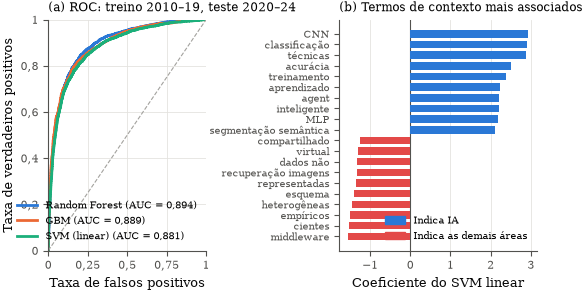

Figura salva em ../data/figuras/fig_classificacao.pdf e .png


In [4]:
svm_exp = LinearSVC(C=0.5, class_weight='balanced', random_state=42).fit(Xtr1, df.loc[tr, 'IA'])
coef = pd.Series(svm_exp.coef_[0], index=v1.get_feature_names_out()).sort_values()
termos_svm = pd.concat([coef.head(15), coef.tail(15)])
termos_svm.to_csv(f'{OUT}/termos_svm.csv', header=['coef'])

info_clf = {
    'n_treino_estrat': len(tr), 'n_teste_estrat': len(te), 
    'n_treino_temp': len(trt), 'n_teste_temp': len(tet),
    'prev_ia_treino_temp': float(df.loc[trt, 'IA'].mean()), 
    'prev_ia_teste_temp': float(df.loc[tet, 'IA'].mean())
}
json.dump({'info': info_clf, 'roc_temporal': roc2, 'roc_estrat': roc1}, open(f'{OUT}/resultados_classificacao.json', 'w'))

# Configuração visual padrão SBC
AZUL, LARANJA, AQUA, VERMELHO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
CINZA, TINTA, TINTA2, GRADE = '#a3a29e', '#0b0b0b', '#52514e', '#e4e3df'
mpl.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8, 'axes.edgecolor': TINTA2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.grid': True,
    'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.axisbelow': True, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'pdf.fonttype': 42,
})
W = 6.3
VIRG = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ',').replace('-', '−'))

fig, axes = plt.subplots(1, 2, figsize=(W, 3.0), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
for nome, cor in [('Random Forest', AZUL), ('GBM', LARANJA), ('SVM (linear)', AQUA)]:
    fpr, tpr = roc2[nome]
    auc_val = met[(met.cenario.str.startswith('Temporal')) & (met.modelo == nome)].auc.item()
    ax.plot(fpr, tpr, color=cor, lw=2, label=f'{nome} (AUC = {auc_val:.3f})'.replace('.', ','))
ax.plot([0, 1], [0, 1], color=CINZA, lw=0.8, ls='--')
ax.set_xlabel('Taxa de falsos positivos')
ax.set_ylabel('Taxa de verdadeiros positivos')
ax.set_title('(a) ROC: treino 2010–19, teste 2020–24', loc='left', fontsize=8.5)
ax.legend(loc='lower right', frameon=False, fontsize=7.2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.0)
ax.xaxis.set_major_formatter(VIRG)
ax.yaxis.set_major_formatter(VIRG)

ax = axes[1]
tm = pd.concat([termos_svm.sort_values().head(10), termos_svm.sort_values().tail(10)])
ac = {
    'acuracia': 'acurácia', 'classificacao': 'classificação', 'tecnicas': 'técnicas', 
    'segmentacao semantica': 'segmentação semântica', 'empiricos': 'empíricos', 
    'recuperacao imagens': 'recuperação imagens', 'gamificacao': 'gamificação', 
    'cientificas': 'científicas', 'eletronica': 'eletrônica', 'cnn': 'CNN', 'mlp': 'MLP', 
    'pso': 'PSO', 'heterogeneas': 'heterogêneas', 'dados nao': 'dados não', 
    'consultas': 'consultas', 'indicador': 'indicador'
}
lab = [ac.get(i, i) for i in tm.index]
ax.barh(range(len(tm)), tm.values, color=[AZUL if v > 0 else VERMELHO for v in tm.values], height=0.7, zorder=3)
ax.set_yticks(range(len(tm)))
ax.set_yticklabels(lab, fontsize=7.3)
ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_xlabel('Coeficiente do SVM linear')
ax.grid(axis='y', visible=False)
ax.set_title('(b) Termos de contexto mais associados', loc='left', fontsize=8.5)
ax.xaxis.set_major_formatter(VIRG)
ax.legend(handles=[Patch(color=AZUL, label='Indica IA'), Patch(color=VERMELHO, label='Indica as demais áreas')], loc='lower right', frameon=False, fontsize=7.3)

# Aumento do wspace para afastar os gráficos
fig.subplots_adjust(wspace=0.75)

fig.savefig(f'{FIG}/fig_classificacao.pdf')
fig.savefig(f'{FIG}/fig_classificacao.png', dpi=300)
plt.show()
print(f"Figura salva em {FIG}/fig_classificacao.pdf e .png")